# Glacier Album: EIC Messages and Source Data

Issue #8. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

**The story this notebook checks, in EIC's own data:**

1. **Breathing**: polar sea ice freezes and thaws every year.
2. **Melting on average**: under that yearly rhythm, the ice keeps shrinking year after year.
3. **Loss**: in 2024 the Arctic melted well below the 1981–2010 normal.
4. **Consequence**: "As the planet warms and polar ice melts, our global average sea level is rising."
5. **Response**: coastal cities plan for it.

Every link used is listed in section 1, so you can check any number against its source.

Run with `npm run notebook`. Downloads go to `data/glacier/raw/` (local only). The sea level section needs a free NASA Earthdata login (see section 6).

In [1]:
import html
import json
import netrc
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/glacier/raw")
(RAW / "api").mkdir(parents=True, exist_ok=True)


def download(name, url, session=None):
    """Download url into data/glacier/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = (session or requests).get(url, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", "", text or "")).strip()


def source_note(ax, text):
    ax.annotate(text, xy=(0, -0.22), xycoords="axes fraction", fontsize=8, color="gray")

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API, so they stay correct if EIC changes.

### 1.1 Where each visualization sits in the EIC gallery

In [2]:
EIC_GALLERY = 40467
PAGES = [5046, 5064, 5099, 5382, 5235, 14713]


def gallery_paths(gallery_id):
    """Map each page id to the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        page = svs_page(page_id)
        if page.get("page_type") != "Gallery":
            paths.setdefault(page_id, []).append(trail)
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    step = f"{group['title']} → [{inst['title']}]({inst['url'].replace('http://', 'https://')})"
                    if inst.get("page_type") == "Gallery" and inst["id"] not in [t[0] for t in trail]:
                        walk(inst["id"], trail + [(inst["id"], step)])
                    elif inst.get("page_type") != "Gallery":
                        paths.setdefault(inst["id"], []).append(trail + [(inst["id"], step)])

    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
rows = ["| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |", "| --- | --- |"]
for page_id in PAGES:
    trails = {" › ".join(step for _, step in trail) for trail in paths.get(page_id, [])}
    rows.append(f"| [{page_id}](https://svs.gsfc.nasa.gov/{page_id}/) | {'<br>'.join(sorted(trails))} |")
display(Markdown("\n".join(rows)))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [5046](https://svs.gsfc.nasa.gov/5046/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Daily Arctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5046/) |
| [5064](https://svs.gsfc.nasa.gov/5064/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Daily Antarctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5064/) |
| [5099](https://svs.gsfc.nasa.gov/5099/) | Daily Visualizations → [Daily Visualizations](https://svs.gsfc.nasa.gov/gallery/daily-visualizations/) › Visualizations → [Daily Polar Sea Ice, Two Year History](https://svs.gsfc.nasa.gov/5099/)<br>EIC Dashboards → [Climate Vital Signs Dashboard](https://svs.gsfc.nasa.gov/gallery/climate-vital-signs-dashboard/) › Visualizations → [Daily Polar Sea Ice, Two Year History](https://svs.gsfc.nasa.gov/5099/) |
| [5382](https://svs.gsfc.nasa.gov/5382/) | EIC Dashboards → [Climate Vital Signs Dashboard](https://svs.gsfc.nasa.gov/gallery/climate-vital-signs-dashboard/) › Visualizations → [Arctic Sea Ice Minimum 2024](https://svs.gsfc.nasa.gov/5382/) |
| [5235](https://svs.gsfc.nasa.gov/5235/) | EIC Dashboards → [Climate Vital Signs Dashboard](https://svs.gsfc.nasa.gov/gallery/climate-vital-signs-dashboard/) › Visualizations → [Sea Level Through a Porthole (2023)](https://svs.gsfc.nasa.gov/5235/) |
| [14713](https://svs.gsfc.nasa.gov/14713/) | EIC Videos → [Building Coastal Resilience with NASA Data](https://svs.gsfc.nasa.gov/14713/) |

### 1.2 What each page cites, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of each SVS page, as published.
- **Downloaded here** is the file this notebook actually reads.
- When EIC gives no download link, we use a substitute and say why.

In [3]:
def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = f"{d['name']} ({d.get('sensor') or d.get('platform')})"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


NSIDC = "https://noaadata.apps.nsidc.org/NOAA/G02135"
GMSL_URL = ("https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/"
            "MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51/GMSL_TPJAOS_5.1.txt")
SEA_ICE_FILES = (f"[Arctic daily]({NSIDC}/north/daily/data/N_seaice_extent_daily_v4.0.csv), "
                 f"[Antarctic daily]({NSIDC}/south/daily/data/S_seaice_extent_daily_v4.0.csv), "
                 f"[Arctic 1981–2010]({NSIDC}/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), "
                 f"[Antarctic 1981–2010]({NSIDC}/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv)")
DOWNLOADED = {
    "sea ice": ("[NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): " + SEA_ICE_FILES,
                "Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account. "
                "NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public."),
    "sea level": (f"[GMSL v5.1 (PO.DAAC)](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51): [GMSL_TPJAOS_5.1.txt]({GMSL_URL})",
                  "The dataset EIC cites (credit and [DOI 10.5067/GMSLM-TJ151](https://doi.org/10.5067/GMSLM-TJ151)). Needs an Earthdata login."),
}
KIND = {5046: "sea ice", 5064: "sea ice", 5099: "sea ice", 5382: "sea ice", 5235: "sea level", 14713: None}

rows = ["| SVS page | Cited by EIC | Downloaded here | Note |", "| --- | --- | --- | --- |"]
for page_id in PAGES:
    page = svs_page(page_id)
    title = f"[{page_id} {page['title']}](https://svs.gsfc.nasa.gov/{page_id}/) ([API](https://svs.gsfc.nasa.gov/api/{page_id}))"
    kind = KIND[page_id]
    used, note = DOWNLOADED[kind] if kind else ("nothing", "Produced video. Message only; its imagery may not be remixed.")
    rows.append(f"| {title} | {cited(page_id)} | {used} | {note} |")
display(Markdown("\n".join(rows)))

| SVS page | Cited by EIC | Downloaded here | Note |
| --- | --- | --- | --- |
| [5046 Daily Arctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5046/) ([API](https://svs.gsfc.nasa.gov/api/5046)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5064 Daily Antarctic Sea Ice, By Year](https://svs.gsfc.nasa.gov/5064/) ([API](https://svs.gsfc.nasa.gov/api/5064)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5099 Daily Polar Sea Ice, Two Year History](https://svs.gsfc.nasa.gov/5099/) ([API](https://svs.gsfc.nasa.gov/api/5099)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5382 Arctic Sea Ice Minimum 2024](https://svs.gsfc.nasa.gov/5382/) ([API](https://svs.gsfc.nasa.gov/api/5382)) | [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/)<br>10 km Daily Sea Ice Concentration (AMSR2), no link<br>10 km Daily 89 GHz Brightness Temperature (AMSR2), no link | [NSIDC Sea Ice Index v4.0 (G02135)](https://nsidc.org/data/g02135): [Arctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_daily_v4.0.csv), [Antarctic daily](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_daily_v4.0.csv), [Arctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/north/daily/data/N_seaice_extent_climatology_1981-2010_v4.0.csv), [Antarctic 1981–2010](https://noaadata.apps.nsidc.org/NOAA/G02135/south/daily/data/S_seaice_extent_climatology_1981-2010_v4.0.csv) | Substitute. EIC names JAXA AMSR2 but gives no link; the raw grids need a JAXA G-Portal account. NSIDC is the source of the numbers EIC quotes in 5382, and its recent values come from the same AMSR2 sensor. Public. |
| [5235 Sea Level Through a Porthole (2023)](https://svs.gsfc.nasa.gov/5235/) ([API](https://svs.gsfc.nasa.gov/api/5235)) | [Global Mean Sea Level (TOPEX/Poseidon, Jason-1, OSTM/Jason-2, and Jason-3)](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_ALL_V51) | [GMSL v5.1 (PO.DAAC)](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51): [GMSL_TPJAOS_5.1.txt](https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51/GMSL_TPJAOS_5.1.txt) | The dataset EIC cites (credit and [DOI 10.5067/GMSLM-TJ151](https://doi.org/10.5067/GMSLM-TJ151)). Needs an Earthdata login. |
| [14713 Building Coastal Resilience with NASA Data](https://svs.gsfc.nasa.gov/14713/) ([API](https://svs.gsfc.nasa.gov/api/14713)) | none | nothing | Produced video. Message only; its imagery may not be remixed. |

## 2. What EIC says

The message of each page, taken from its description (or its longest caption when the description is only a heading).

In [4]:
def message(page_id):
    page = svs_page(page_id)
    text = plain(page["description"].split(" || ")[0])
    if len(text) < 100:
        texts = [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
        text = max(texts, key=len)
    return text


display(Markdown("\n\n".join(f"**[{i}](https://svs.gsfc.nasa.gov/{i}/) {svs_page(i)['title']}**\n\n> {message(i)[:700]}"
                               for i in PAGES)))

**[5046](https://svs.gsfc.nasa.gov/5046/) Daily Arctic Sea Ice, By Year**

> This visualization shows the daily Arctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day (available from the drop-down of each image window), and an animation created from these frames. The Japan Aerospace Exploration Agency (JAXA) provides many water-related products derived from data acquired by the Advanced Microwave Scanning Radiometer 2 (AMSR2) instrument aboard the Global Change Observation Mission 1st-Water "SHIZUKU" (GCOM-W1) satellite. Two JAXA datasets are used in this animation:  the 10-km daily sea ice concentration and the 10 km daily 89 GHz Brightness Temperature.In this visualization sea ice changes from day to day, w

**[5064](https://svs.gsfc.nasa.gov/5064/) Daily Antarctic Sea Ice, By Year**

> This visualization shows the daily Antarctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day (available from the drop-down of each image window), and an animation created from these frames. The Japan Aerospace Exploration Agency (JAXA) provides many water-related products derived from data acquired by the Advanced Microwave Scanning Radiometer 2 (AMSR2) instrument aboard the Global Change Observation Mission 1st-Water "SHIZUKU" (GCOM-W1) satellite. Two JAXA datasets are used in this animation:  the 10-km daily sea ice concentration and the 10 km daily 89 GHz Brightness Temperature.In this visualization sea ice changes from day to day

**[5099](https://svs.gsfc.nasa.gov/5099/) Daily Polar Sea Ice, Two Year History**

> This visualization shows the daily Arctic and Antarctic sea ice and seasonal land cover change over a two-year history from the present, with a single frame rendered for each day (available from the drop-down of each image window), and an animation created from these frames, The Japan Aerospace Exploration Agency (JAXA) provides many water-related products derived from data acquired by the Advanced Microwave Scanning Radiometer 2 (AMSR2) instrument aboard the Global Change Observation Mission 1st-Water "SHIZUKU" (GCOM-W1) satellite. Two JAXA datasets are used in this animation: the 10-km daily sea ice concentration and the 10 km daily 89 GHz Brightness Temperature.In this visualization sea i

**[5382](https://svs.gsfc.nasa.gov/5382/) Arctic Sea Ice Minimum 2024**

> Satellite-based passive microwave images of the sea ice have provided a reliable tool for continuously monitoring changes in the Arctic ice since 1979. Every summer the Arctic ice cap melts down to what scientists call its "minimum" before colder weather begins to cause ice cover to increase. An analysis of satellite data by NASA and the National Snow and Ice Data Center (NSIDC) at the University of Colorado Boulder shows that the 2024 minimum extent, which was likely reached on Sept. 11, measured 1.65 million square miles (4.28 million square kilometers). This is the 7th lowest measured sea ice extent for the arctic on record.The Japan Aerospace Exploration Agency (JAXA) provides many water

**[5235](https://svs.gsfc.nasa.gov/5235/) Sea Level Through a Porthole (2023)**

> As the planet warms and polar ice melts, our global average sea level is rising. Although exact ocean heights vary due to local geography, climate over time, and dynamic fluid interactions with gravity and planetary rotation, scientists observe sea level trends by comparing measurements against a 20 year spatial and temporal mean reference. These visualizations use the visual metaphor of a submerged porthole window to observe how far our oceans rose between 1993 and 2023.

**[14713](https://svs.gsfc.nasa.gov/14713/) Building Coastal Resilience with NASA Data**

> The city of Mobile, AL is working with NASA’s Sea Level Change Team to plan for future infrastructure projects and to protect Mobile’s coastal resources. As sea levels change globally, coastal cities feel the effects of more frequent and more severe storms and flooding. NASA’s sea level change data helps Mobile and other coastal communities plan for a more resilient future.

## 3. Source data: sea ice extent

**NSIDC Sea Ice Index v4.0** ([dataset page](https://nsidc.org/data/g02135)). Links to each file are in section 1.2.

- **Extent**: area of ocean with at least 15% ice cover, in million km²
- **Daily**, Oct 1978 to now (every other day before Aug 1987)
- **1981–2010 climatology**: the "normal" EIC compares against, per day of year

Credit: Fetterer, F., et al. Sea Ice Index, Version 4. NSIDC. [doi:10.7265/a98x-0f50](https://doi.org/10.7265/a98x-0f50)

> **Sea ice is not glacier ice.** Sea ice is frozen seawater floating on the ocean. When it melts it barely changes sea level, because it already displaces its own weight of water. Sea level rises when **land ice** melts (glaciers and the ice sheets of Greenland and Antarctica) and when seawater warms and expands. Sea ice decline and sea level rise are both signs of the same warming, which is why EIC shows them side by side.

In [5]:
POLE = {"N": "north", "S": "south"}
NAME = {"N": "Arctic", "S": "Antarctic"}


def sea_ice_daily(h):
    name = f"{h}_seaice_extent_daily_v4.0.csv"
    path = download(name, f"{NSIDC}/{POLE[h]}/daily/data/{name}")
    df = pd.read_csv(path, skiprows=[1], skipinitialspace=True, usecols=[0, 1, 2, 3])
    df.columns = ["year", "month", "day", "extent"]
    df["date"] = pd.to_datetime(df[["year", "month", "day"]])
    # Fill single missing days (every other day before 1987) so rolling averages work.
    return df.set_index("date")["extent"].asfreq("D").interpolate(limit=2)


def sea_ice_normal(h):
    name = f"{h}_seaice_extent_climatology_1981-2010_v4.0.csv"
    path = download(name, f"{NSIDC}/{POLE[h]}/daily/data/{name}")
    df = pd.read_csv(path, skiprows=1, skipinitialspace=True)
    df.columns = ["doy", "mean", "std", "p10", "p25", "p50", "p75", "p90"]
    return df.set_index("doy")


ice = {h: sea_ice_daily(h) for h in "NS"}
normal = {h: sea_ice_normal(h) for h in "NS"}
FULL_YEARS = range(1979, ice["N"].index.max().year)  # complete years only
print({NAME[h]: f"{s.index.min().date()} to {s.index.max().date()}" for h, s in ice.items()})

{'Arctic': '1978-10-26 to 2026-11-12', 'Antarctic': '1978-10-26 to 2026-11-12'}


## 4. Message 1, breathing: the poles freeze and thaw every year

[5046](https://svs.gsfc.nasa.gov/5046/), [5064](https://svs.gsfc.nasa.gov/5064/), [5099](https://svs.gsfc.nasa.gov/5099/)

> "This visualization shows the daily Arctic sea ice and seasonal land cover change progressing through time, with a single frame rendered for each day."

EIC shows 2021 to 2024. Same years from the source data, against the 1981–2010 normal:

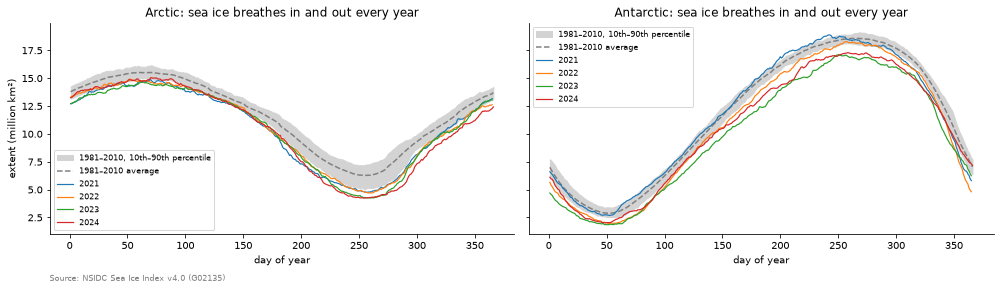

In [6]:
YEARS = [2021, 2022, 2023, 2024]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, h in zip(axes, "NS"):
    norm = normal[h]
    ax.fill_between(norm.index, norm["p10"], norm["p90"], color="lightgray", label="1981–2010, 10th–90th percentile")
    ax.plot(norm.index, norm["mean"], color="gray", linestyle="--", label="1981–2010 average")
    for year in YEARS:
        s = ice[h][str(year)]
        ax.plot(s.index.day_of_year, s.values, linewidth=1.2, label=str(year))
    ax.set_title(f"{NAME[h]}: sea ice breathes in and out every year")
    ax.set_xlabel("day of year")
    ax.legend(fontsize=8)
axes[0].set_ylabel("extent (million km²)")
source_note(axes[0], "Source: NSIDC Sea Ice Index v4.0 (G02135)")
plt.tight_layout()

In [7]:
def yearly_cycle(h, years):
    f5 = ice[h].rolling(5).mean()  # NSIDC reports minima and maxima on a 5-day trailing average
    f5 = f5[f5.index.year.isin(years)]
    g = f5.groupby(f5.index.year)
    out = pd.DataFrame({"max": g.max(), "max date": g.idxmax().dt.strftime("%b %d"),
                        "min": g.min(), "min date": g.idxmin().dt.strftime("%b %d")})
    out["swing (max - min)"] = out["max"] - out["min"]
    return out.round(2)


pd.concat({NAME[h]: yearly_cycle(h, YEARS) for h in "NS"})

max max date   min min date  swing (max - min)
          date                                                  
Arctic    2021  14.78   Mar 12  4.77   Sep 16              10.01
          2022  14.84   Feb 25  4.70   Sep 19              10.14
          2023  14.62   Mar 06  4.26   Sep 19              10.36
          2024  15.02   Mar 14  4.25   Sep 14              10.77
Antarctic 2021  18.84   Sep 01  2.70   Feb 24              16.14
          2022  18.25   Sep 16  1.98   Feb 25              16.27
          2023  17.07   Sep 09  1.85   Feb 21              15.21
          2024  17.26   Sep 16  2.03   Feb 20              15.23

- Every year the Arctic swings by about 10 million km² and the Antarctic by 15 to 16 million km².
- The poles breathe in **opposite phase**: the Arctic peaks in March and bottoms out in September, the Antarctic the other way round.
- Over four years the yearly rhythm dominates. To see the trend, step back to the whole record (next section).

## 5. Message 2, melting on average: the ice keeps shrinking

The yearly rhythm hides a slow decline. Averaging each year removes the seasons and leaves the trend. This section is our computation from the source data; it backs EIC's message that "polar ice melts" ([5235](https://svs.gsfc.nasa.gov/5235/)).

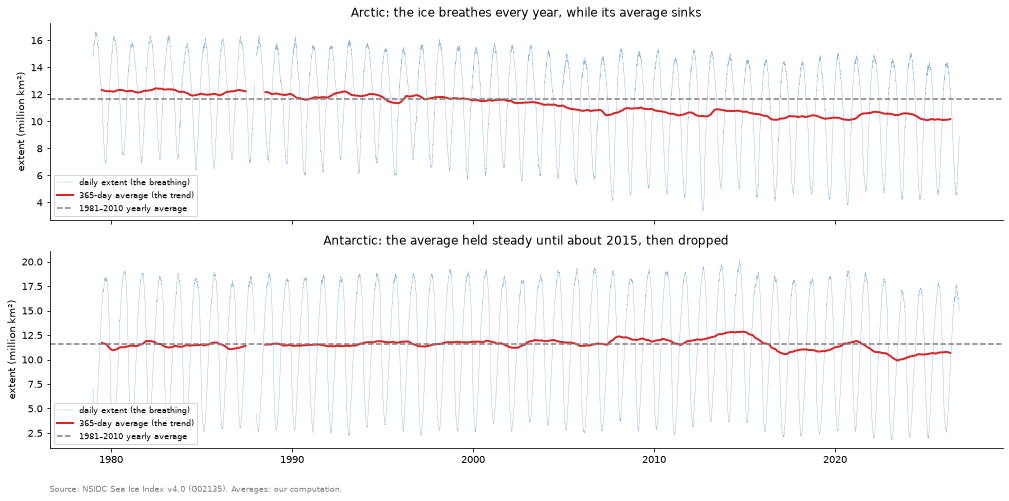

In [8]:
TITLES = {"N": "Arctic: the ice breathes every year, while its average sinks",
          "S": "Antarctic: the average held steady until about 2015, then dropped"}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, h in zip(axes, "NS"):
    s = ice[h]["1979":]
    yearly = s.rolling(365, center=True).mean()
    ax.plot(s.index, s.values, color="tab:blue", linewidth=0.4, alpha=0.5, label="daily extent (the breathing)")
    ax.plot(yearly.index, yearly.values, color="tab:red", linewidth=2, label="365-day average (the trend)")
    ax.axhline(normal[h]["mean"].mean(), color="gray", linestyle="--", label="1981–2010 yearly average")
    ax.set_title(TITLES[h])
    ax.set_ylabel("extent (million km²)")
    ax.legend(fontsize=8, loc="lower left")
source_note(axes[1], "Source: NSIDC Sea Ice Index v4.0 (G02135). Averages: our computation.")
plt.tight_layout()

,1979–1988 average,2016–2025 average,change (%),lowest year
Arctic,12.19,10.35,-15.13,2025
Antarctic,11.48,10.88,-5.27,2023
Both poles,23.67,21.22,-10.35,2023


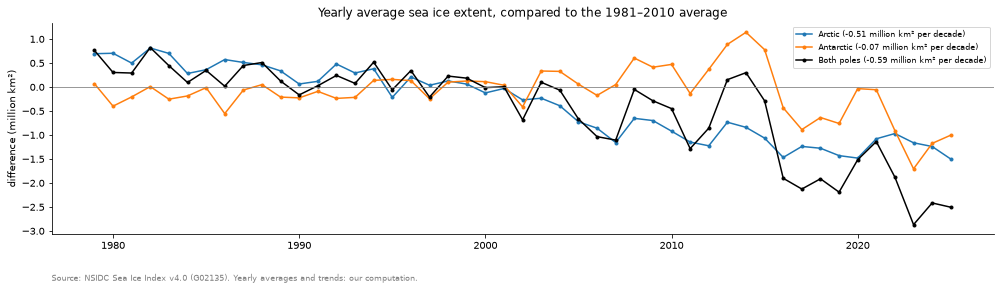

In [9]:
annual = pd.DataFrame({NAME[h]: ice[h].groupby(ice[h].index.year).mean() for h in "NS"}).loc[FULL_YEARS]
annual["Both poles"] = annual["Arctic"] + annual["Antarctic"]

fig, ax = plt.subplots(figsize=(14, 4.2))
for col, color in [("Arctic", "tab:blue"), ("Antarctic", "tab:orange"), ("Both poles", "black")]:
    anomaly = annual[col] - annual.loc[1981:2010, col].mean()
    trend = np.polyfit(anomaly.index, anomaly.values, 1)
    ax.plot(anomaly.index, anomaly.values, marker="o", markersize=3, color=color,
            label=f"{col} ({trend[0] * 10:+.2f} million km² per decade)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Yearly average sea ice extent, compared to the 1981–2010 average")
ax.set_ylabel("difference (million km²)")
ax.legend(fontsize=8)
source_note(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135). Yearly averages and trends: our computation.")
plt.tight_layout()

change = pd.DataFrame({
    "1979–1988 average": annual.loc[1979:1988].mean(),
    f"{FULL_YEARS[-1] - 9}–{FULL_YEARS[-1]} average": annual.loc[FULL_YEARS[-1] - 9:].mean(),
})
change["change (%)"] = (change.iloc[:, 1] / change.iloc[:, 0] - 1) * 100
change["lowest year"] = annual.idxmin()
change.round(2)

What the data says:

- **Arctic**: a steady decline since 1979. The last ten years average about 15% less ice than the first ten.
- **Antarctic**: no decline until about 2015, then a sharp drop; 2023 is its lowest year on record. The two poles do not change the same way.
- **Both poles together**: less ice than the 1981–2010 average in every recent year.

**Track data**: the 365-day average per pole (one value per day since 1979), or the yearly averages (one value per year). Played under the daily breathing, it becomes a floor that slowly sinks.

## 6. Message 3, loss: the Arctic melts below the old normal

[5382](https://svs.gsfc.nasa.gov/5382/)

> "Every summer the Arctic ice cap melts down to what scientists call its 'minimum' [...] the 2024 minimum extent, which was likely reached on Sept. 11, measured 1.65 million square miles (4.28 million square kilometers). This is the 7th lowest measured sea ice extent for the arctic on record. [...] The yellow boundary shows the minimum extent averaged over the 30-year period from 1981 to 2010."

The animation runs from the 2024 maximum (March 14) to the minimum (Sept 11).

Gap to the 1981–2010 average: 0.46 million km² on Mar 14, 2.01 on Sep 11, largest 2.17


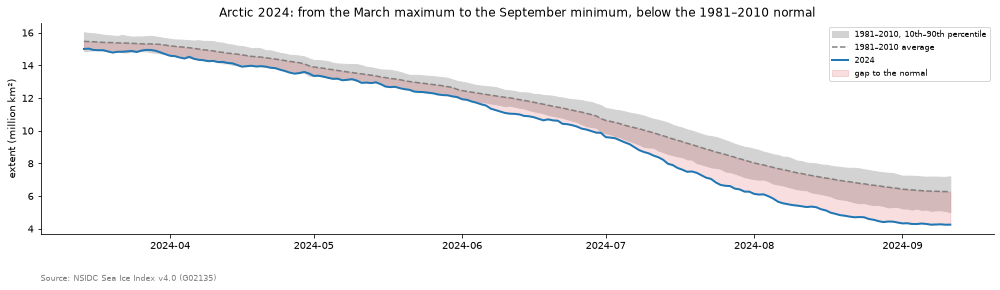

In [10]:
melt = ice["N"]["2024-03-14":"2024-09-11"]
norm = normal["N"].loc[melt.index.day_of_year]
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.fill_between(melt.index, norm["p10"], norm["p90"], color="lightgray", label="1981–2010, 10th–90th percentile")
ax.plot(melt.index, norm["mean"].values, color="gray", linestyle="--", label="1981–2010 average")
ax.plot(melt.index, melt.values, color="tab:blue", linewidth=2, label="2024")
ax.fill_between(melt.index, melt.values, norm["mean"].values, color="tab:red", alpha=0.15, label="gap to the normal")
ax.set_title("Arctic 2024: from the March maximum to the September minimum, below the 1981–2010 normal")
ax.set_ylabel("extent (million km²)")
ax.legend(fontsize=8)
source_note(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135)")
plt.tight_layout()

gap = norm["mean"].values - melt.values
print(f"Gap to the 1981–2010 average: {gap[0]:.2f} million km² on Mar 14, {gap[-1]:.2f} on Sep 11, largest {gap.max():.2f}")

,"EIC (5382, Sept 2024)",NSIDC v4.0 (this notebook)
2024 minimum,4.28 million km²,4.25 million km²
date,Sept 11,Sep 14
rank since 1979,7th lowest,6th lowest


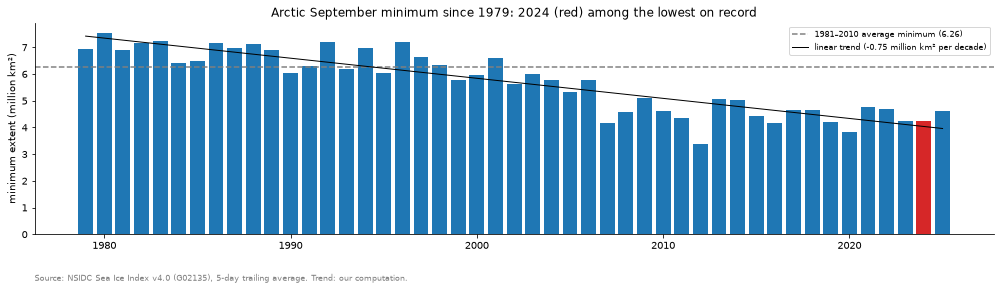

In [11]:
f5 = ice["N"].rolling(5).mean()
minima = f5.groupby(f5.index.year).agg(["min", "idxmin"]).loc[FULL_YEARS]
minima.columns = ["minimum", "date"]
minima["rank (1 = lowest)"] = minima["minimum"].rank().astype(int)
normal_min = normal["N"]["mean"].min()

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.bar(minima.index, minima["minimum"], color=["tab:red" if y == 2024 else "tab:blue" for y in minima.index])
ax.axhline(normal_min, color="gray", linestyle="--", label=f"1981–2010 average minimum ({normal_min:.2f})")
trend = np.polyfit(minima.index, minima["minimum"], 1)
ax.plot(minima.index, np.polyval(trend, minima.index), color="black", linewidth=1,
        label=f"linear trend ({trend[0] * 10:+.2f} million km² per decade)")
ax.set_title("Arctic September minimum since 1979: 2024 (red) among the lowest on record")
ax.set_ylabel("minimum extent (million km²)")
ax.legend(fontsize=8)
source_note(ax, "Source: NSIDC Sea Ice Index v4.0 (G02135), 5-day trailing average. Trend: our computation.")
plt.tight_layout()

pd.DataFrame({
    "EIC (5382, Sept 2024)": ["4.28 million km²", "Sept 11", "7th lowest"],
    "NSIDC v4.0 (this notebook)": [f"{minima.loc[2024, 'minimum']:.2f} million km²",
                                   minima.loc[2024, "date"].strftime("%b %d"),
                                   f"{minima.loc[2024, 'rank (1 = lowest)']}th lowest"],
}, index=["2024 minimum", "date", "rank since 1979"])

- 2024 stays below the normal for the whole melt season, and the gap widens toward September.
- Our numbers differ slightly from EIC's: NSIDC reprocessed the Sea Ice Index (version 4.0) after the September 2024 announcement. The message holds: 2024 is one of the lowest years on record.

**Track data**: the 2024 melt (182 days) together with the normal for the same days, so the gap can be heard. Or the yearly minimum since 1979 as a slow descending line.

## 7. Message 4, consequence: the sea rises

[5235](https://svs.gsfc.nasa.gov/5235/)

> "As the planet warms and polar ice melts, our global average sea level is rising. [...] These visualizations use the visual metaphor of a submerged porthole window to observe how far our oceans rose between 1993 and 2023."
>
> "The blue mark on the ruler shows the exact measurements [...]. The level of the animated water changes more smoothly, driven by a 60-day floating average of the same data."

**Source: Global Mean Sea Level v5.1**, NASA Goddard Space Flight Center, the dataset EIC cites ([PO.DAAC](https://podaac.jpl.nasa.gov/dataset/MERGED_TP_J1_OSTM_OST_GMSL_ASCII_V51), [DOI](https://doi.org/10.5067/GMSLM-TJ151)). Satellite altimeters TOPEX/Poseidon, Jason-1, Jason-2, Jason-3 and Sentinel-6; one value about every 10 days; mm relative to a 20-year mean.

**To download it**, create a free account at [urs.earthdata.nasa.gov](https://urs.earthdata.nasa.gov/users/new) and add this line to `~/.netrc` (never commit it):

```
machine urs.earthdata.nasa.gov login <username> password <password>
```

In [12]:
def has_earthdata_login():
    try:
        return netrc.netrc().authenticators("urs.earthdata.nasa.gov") is not None
    except (FileNotFoundError, netrc.NetrcParseError):
        return False


def read_gmsl(path):
    lines = path.read_text().splitlines()
    rows = [line.split() for line in lines if line.strip() and not line.startswith("HDR")]
    df = pd.DataFrame(rows).astype(float)
    # Column meanings from the file header (HDR lines): 3 = year + fraction, 9 = GMSL with GIA applied (mm),
    # 11 = the same, 60-day smoothed.
    df = df.rename(columns={2: "year", 8: "gmsl", 10: "gmsl_smooth"})
    df["date"] = pd.to_datetime("1993-01-01") + pd.to_timedelta((df["year"] - 1993) * 365.25, unit="D")
    header = [line for line in lines if line.startswith("HDR") and re.match(r"HDR\s+\d+\s", line)]
    return df, header


gmsl = None
GMSL_FILE = "GMSL_TPJAOS_5.1.txt"
if (RAW / GMSL_FILE).exists() or has_earthdata_login():
    # requests reads ~/.netrc and re-applies it on the redirect to urs.earthdata.nasa.gov.
    gmsl, header = read_gmsl(download(GMSL_FILE, GMSL_URL, session=requests.Session()))
    print("\n".join(header))
    print(f"\nGMSL: {len(gmsl)} values, {gmsl['date'].min().date()} to {gmsl['date'].max().date()}")
else:
    display(Markdown("**Skipped**: no Earthdata login in `~/.netrc`. See the instructions above."))

**Skipped**: no Earthdata login in `~/.netrc`. See the instructions above.

In [13]:
if gmsl is not None:
    eic_period = gmsl[(gmsl["date"] >= "1993-01-01") & (gmsl["date"] <= "2023-12-31")]
    fig, ax = plt.subplots(figsize=(14, 4.2))
    ax.plot(gmsl["date"], gmsl["gmsl"], ".", markersize=2, color="tab:blue", alpha=0.4, label="measurements (the blue mark)")
    ax.plot(gmsl["date"], gmsl["gmsl_smooth"], color="tab:blue", linewidth=1.5, label="60-day smoothed (the animated water)")
    ax.axvspan(pd.Timestamp("1993-01-01"), pd.Timestamp("2023-12-31"), color="lightgray", alpha=0.3, label="period EIC shows")
    ax.set_title("Global mean sea level: rising as the planet warms and polar ice melts")
    ax.set_ylabel("sea level change (mm)")
    ax.legend(fontsize=8)
    source_note(ax, "Source: NASA GSFC Global Mean Sea Level v5.1 (PO.DAAC), GIA applied")
    plt.tight_layout()

    smooth = eic_period.set_index("date")["gmsl_smooth"]
    rise = smooth.iloc[-36:].mean() - smooth.iloc[:36].mean()
    fit = np.polyfit(gmsl["year"], gmsl["gmsl"], 2)
    print(f"Rise from 1993 to 2023 (smoothed, first year vs last year): about {rise:.0f} mm")
    print(f"Rate in {gmsl['year'].iloc[-1]:.0f} (quadratic fit, our computation): {np.polyval(np.polyder(fit), gmsl['year'].iloc[-1]):.1f} mm/year")

### 7.1 Ice and sea, side by side

The same years for both: polar sea ice (sections 4–6) and global sea level. Two symptoms of one warming planet, not one causing the other (see the note in section 3).

In [14]:
if gmsl is not None:
    years = range(1993, FULL_YEARS[-1] + 1)
    sea = gmsl.groupby(gmsl["year"].astype(int))["gmsl"].mean().reindex(years)
    arctic = annual["Arctic"].reindex(years)

    fig, ax1 = plt.subplots(figsize=(14, 4.2))
    ax1.plot(arctic.index, arctic.values, color="tab:blue", marker="o", markersize=3, label="Arctic sea ice, yearly average")
    ax1.set_ylabel("sea ice extent (million km²)", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(sea.index, sea.values, color="tab:red", marker="o", markersize=3, label="global mean sea level, yearly average")
    ax2.set_ylabel("sea level change (mm)", color="tab:red")
    ax1.set_title("As polar ice shrinks, the sea rises (1993 to now)")
    source_note(ax1, "Sources: NSIDC Sea Ice Index v4.0; NASA GSFC GMSL v5.1. Yearly averages: our computation.")
    plt.tight_layout()
else:
    display(Markdown("Shown once the sea level data is downloaded."))

Shown once the sea level data is downloaded.

**Track data**: the 60-day smoothed sea level (one value about every 10 days, 1993 to now) as a slowly rising floor, with the raw measurements as a ripple on top.

**Message 5, response** ([14713](https://svs.gsfc.nasa.gov/14713/)) is a produced video with no data of its own. Its imagery may not be remixed, so the album uses its message only.

> If the album needs the direct cause of sea level rise, melting **glaciers and ice sheets**, it has to add land ice data from outside the EIC gallery (for example NASA's GRACE ice sheet mass measurements).

## 8. Message summary

In [15]:
arctic_change = change.loc["Arctic", "change (%)"]
summary = pd.DataFrame([
    {"message": "Breathing: the poles freeze and thaw every year", "EIC pages": "5046, 5064, 5099",
     "key numbers": "yearly swing about 10 (Arctic) and 15–16 (Antarctic) million km², opposite phases",
     "source": "NSIDC Sea Ice Index v4.0"},
    {"message": "Melting on average: the ice keeps shrinking", "EIC pages": "5235 (\"polar ice melts\")",
     "key numbers": f"Arctic yearly average {arctic_change:.0f}% since 1979–1988; Antarctic lowest in "
                    f"{int(change.loc['Antarctic', 'lowest year'])}",
     "source": "NSIDC Sea Ice Index v4.0, our computation"},
    {"message": "Loss: the Arctic melts below the old normal", "EIC pages": "5382",
     "key numbers": f"2024 minimum {minima.loc[2024, 'minimum']:.2f} million km², "
                    f"{minima.loc[2024, 'rank (1 = lowest)']}th lowest since 1979; normal minimum {normal_min:.2f}",
     "source": "NSIDC Sea Ice Index v4.0"},
    {"message": "Consequence: the sea rises", "EIC pages": "5235",
     "key numbers": "needs an Earthdata login" if gmsl is None else f"about {rise:.0f} mm from 1993 to 2023",
     "source": "NASA GSFC GMSL v5.1"},
    {"message": "Response: coastal cities adapt", "EIC pages": "14713", "key numbers": "-", "source": "message only"},
])
summary

,message,EIC pages,key numbers,source
0,Breathing: the poles freeze and thaw every year,"5046, 5064, 5099","yearly swing about 10 (Arctic) and 15–16 (Antarctic) million km², opposite phases",NSIDC Sea Ice Index v4.0
1,Melting on average: the ice keeps shrinking,"5235 (""polar ice melts"")",Arctic yearly average -15% since 1979–1988; Antarctic lowest in 2023,"NSIDC Sea Ice Index v4.0, our computation"
2,Loss: the Arctic melts below the old normal,5382,"2024 minimum 4.25 million km², 6th lowest since 1979; normal minimum 6.26",NSIDC Sea Ice Index v4.0
3,Consequence: the sea rises,5235,needs an Earthdata login,NASA GSFC GMSL v5.1
4,Response: coastal cities adapt,14713,-,message only


## 9. Track candidates

The data series each message offers. "values" is the number of data points; the album decides how fast to play them.

In [16]:
def describe(name, msg, series, unit):
    series = series.dropna()
    return {"track candidate": name, "message": msg, "values": len(series),
            "from": series.index.min().date(), "to": series.index.max().date(),
            "min": round(series.min(), 2), "max": round(series.max(), 2), "unit": unit}


def yearly_index(series):
    return series.set_axis(pd.to_datetime(series.index.astype(str)))


tracks = [describe(f"{NAME[h]} {y}", "breathing", ice[h][str(y)], "million km²") for h in "NS" for y in YEARS]
for h in "NS":
    recent = ice[h][ice[h].index.max() - pd.DateOffset(years=2):]
    tracks.append(describe(f"{NAME[h]}, last two years (pair with the other pole)", "breathing", recent, "million km²"))
    tracks.append(describe(f"{NAME[h]}, 365-day average since 1979", "melting on average",
                           ice[h]["1979":].rolling(365, center=True).mean(), "million km²"))
    tracks.append(describe(f"{NAME[h]}, yearly average since 1979", "melting on average", yearly_index(annual[NAME[h]]), "million km²"))
tracks.append(describe("Arctic melt 2024 (Mar 14 to Sep 11)", "loss", melt, "million km²"))
tracks.append(describe("Arctic September minimum since 1979", "loss", yearly_index(minima["minimum"]), "million km²"))
if gmsl is not None:
    tracks.append(describe("Global mean sea level since 1993", "consequence", gmsl.set_index("date")["gmsl_smooth"], "mm"))
pd.DataFrame(tracks)

,track candidate,message,values,from,to,min,max,unit
0,Arctic 2021,breathing,365,2021-01-01,2021-12-31,4.76,14.86,million km²
1,Arctic 2022,breathing,365,2022-01-01,2022-12-31,4.69,14.94,million km²
2,Arctic 2023,breathing,365,2023-01-01,2023-12-31,4.24,14.64,million km²
3,Arctic 2024,breathing,366,2024-01-01,2024-12-31,4.24,15.04,million km²
4,Antarctic 2021,breathing,365,2021-01-01,2021-12-31,2.68,18.89,million km²
5,Antarctic 2022,breathing,365,2022-01-01,2022-12-31,1.96,18.28,million km²
6,Antarctic 2023,breathing,365,2023-01-01,2023-12-31,1.85,17.11,million km²
7,Antarctic 2024,breathing,366,2024-01-01,2024-12-31,2.02,17.28,million km²
8,"Arctic, last two years (pair with the other pole)",breathing,731,2024-11-12,2026-11-12,4.54,14.36,million km²
9,"Arctic, 365-day average since 1979",melting on average,16716,1979-07-02,2026-05-14,10.09,12.44,million km²


## Next steps

- Choose the tracks and their order.
- Decide how each series maps to sound, and how fast each track plays.
- Export the chosen series into `data/glacier/tracks/` with a `tracks.json` ([data-guide.md](../docs/data-guide.md)).